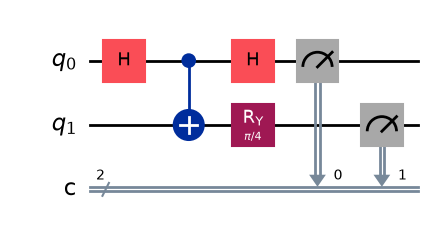

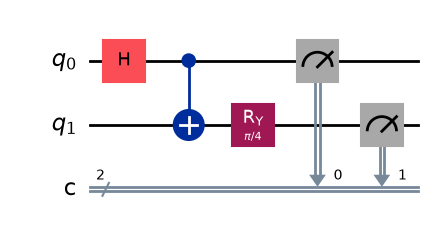

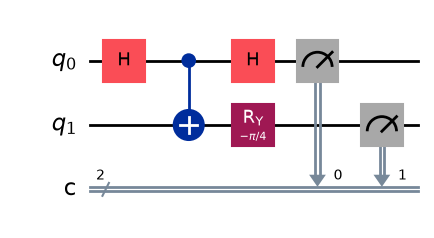

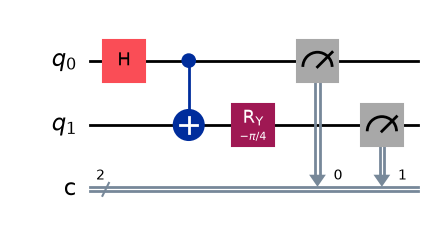


Il valore  misurato del valore di aspettazione E1 è -0.7116
Il valore  misurato del valore di aspettazione E2 è 0.6926
Il valore  misurato del valore di aspettazione E3 è 0.7154
Il valore  misurato del valore di aspettazione E4 è 0.71

Il valore della combinazione lineare dei valori di aspettazions S è 2.8296


In [ ]:
"""
===========================================================================
Violazione della Disuguaglianza CHSH (Test del Realismo Locale)
===========================================================================
Questo script dimostra la violazione della disuguaglianza di Bell, provando 
che la meccanica quantistica è incompatibile con il realismo locale (ovvero 
le teorie a variabili nascoste locali).

Fasi del programma:
1. Preparazione: Crea una coppia di qubit in uno stato entangled (H + CX).
2. Basi di misura: Definisce 4 circuiti per misurare in direzioni diverse 
   (assi X e Z per il Qubit 0; rotazioni di ±π/4 per il Qubit 1).
3. Esecuzione: Simula i quattro circuiti per 10.000 volte (shots).
4. Correlazioni: Calcola i 4 valori di aspettazione (E1, E2, E3, E4) dalla 
   differenza tra esiti concordi (00, 11) e discordi (01, 10).
5. Risultato: Calcola il parametro CHSH (S = -E1 + E2 + E3 + E4). 

Il superamento del limite classico (|S| <= 2) confuta il realismo locale, 
avvicinandosi al limite quantistico di Tsirelson (2√2 ≈ 2.828).

NOTA TEORICA:
- Nel caso CLASSICO (realismo locale), si assume che i risultati delle misure siano 
  già definiti a priori (±1). Calcolando S su questi valori preesistenti, il 
  risultato per ogni singolo evento è matematicamente limitato a |S| <= 2.
- Nel caso QUANTISTICO, le particelle non possiedono valori definiti prima della 
  misura; il singolo esito è probabilistico. Pertanto, S non può essere calcolato 
  per un singolo evento, ma si ricava dalla media statistica (valori di aspettazione) 
  su migliaia di ripetizioni (shots).
"""


import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_bloch_multivector, 
    plot_state_qsphere,
    circuit_drawer, 
    plot_histogram
)

#Circuito 1 (asse X e +pi/4)
qc1 = QuantumCircuit(2,2)
qc1.h(0)
qc1.cx(0,1)

qc1.h(0)
qc1.ry(np.pi/4, 1)

qc1.measure([0,1],[0,1])

#Circuito 2 (asse Z e +pi/4)
qc2 = QuantumCircuit(2,2)
qc2.h(0)
qc2.cx(0,1)

qc2.ry(np.pi/4,1)

qc2.measure([0,1],[0,1])

#Circuito 3 (asse X e -pi/4)
qc3 = QuantumCircuit(2,2)
qc3.h(0)
qc3.cx(0,1)

qc3.h(0)
qc3.ry(-np.pi/4,1)

qc3.measure([0,1],[0,1])

#Circuito 4 (asse Z e -pi/4)
qc4 = QuantumCircuit(2,2)
qc4.h(0)
qc4.cx(0,1)

qc4.ry(-np.pi/4,1)

qc4.measure([0,1],[0,1])

# Misurazione dei quattro circuiti
simulator = AerSimulator()

job1 = simulator.run(qc1, shots = 10000)
result1= job1.result()
counts1 = result1.get_counts()
n1_00 = counts1.get('00', 0)
n1_01 = counts1.get('01', 0)
n1_10 = counts1.get('10', 0)
n1_11 = counts1.get('11', 0)
E1 = ((n1_00 + n1_11)-(n1_01 + n1_10))/10000


job2 = simulator.run(qc2, shots = 10000)
result2 = job2.result()
counts2 = result2.get_counts()
n2_00 = counts2.get('00', 0)
n2_01 = counts2.get('01', 0)
n2_10 = counts2.get('10', 0)
n2_11 = counts2.get('11', 0)
E2 = ((n2_00 + n2_11)-(n2_01 + n2_10))/10000

job3 = simulator.run(qc3, shots = 10000)
result3 = job3.result()
counts3 = result3.get_counts()
n3_00 = counts3.get('00', 0)
n3_01 = counts3.get('01', 0)
n3_10 = counts3.get('10', 0)
n3_11 = counts3.get('11', 0)
E3 = ((n3_00 + n3_11)-(n3_01 + n3_10))/10000

job4 = simulator.run(qc4, shots = 10000)
result4 = job4.result()
counts4 = result4.get_counts()
n4_00 = counts4.get('00', 0)
n4_01 = counts4.get('01', 0)
n4_10 = counts4.get('10', 0)
n4_11 = counts4.get('11', 0)
E4 = ((n4_00 + n4_11)-(n4_01 + n4_10))/10000

#Rappresentazione Circuiti

q1 = qc1.draw("mpl")
display(q1)
q2 = qc2.draw("mpl")
display(q2)
q3 = qc3.draw("mpl")
display(q3)
q4 = qc4.draw("mpl")
display(q4)

# Output: valori di aspettazione e valore della loro combinazione lineare S
S = -E1 +E2 + E3 +E4 
print(f"\nIl valore  misurato del valore di aspettazione E1 è {E1}")
print(f"Il valore  misurato del valore di aspettazione E2 è {E2}")
print(f"Il valore  misurato del valore di aspettazione E3 è {E3}")
print(f"Il valore  misurato del valore di aspettazione E4 è {E4}")

print(f"\nIl valore della combinazione lineare dei valori di aspettazions S è {S}")






